# TELEPATI-ABF | YOLO26n + Class-Aware Augmentation + Feature Knowledge Distillation

**A + B + F** untuk 11 kelas penyakit padi pada dataset COCO yang dipakai notebook TELEPATI sebelumnya.

- **A — Extended fine-tuning:** YOLO26n student dilatih hingga **100 epoch** dengan `patience=20` dan `close_mosaic=10`.
- **B — Class-aware augmentation:** training-only image re-sampling yang memprioritaskan kelas langka **tanpa menghapus anotasi kelas lain**, ditambah augmentasi geometris/warna ringan secara online.
- **F — True feature-level KD:** YOLO26s teacher di-fine-tune pada dataset asli; student YOLO26n memakai `distill_model=<teacher_best.pt>` dan `dis` pada Ultralytics.

**Eval utama:** macro detection-F1 @ IoU=0.50. Confidence threshold ditentukan hanya lewat `valid`, lalu `test` digunakan sekali dengan konfigurasi tetap. Sekalian evaluasi mAP50 dan mAP50–95 Ultralytics.

Notebook siap untuk **Kaggle** (auto-detect `/kaggle/input`) dan **Colab** (dataset folder/ZIP di `/content`). GPU dibutuhkan. Tidak menjalankan model ketika file ini dibuat; angka hasil berasal dari eksekusi notebook di GPU.

**Perhatian data:** pemetaan kelas 0 mempertahankan alias `paddy` dan `Rice-Leaf-Diseasee` dari notebook asli; keduanya harus ditinjau karena tidak secara otomatis berarti bacterial leaf blight. Sel peringatan akan menampilkan jumlahnya.

Referensi: [Ultralytics — Knowledge Distillation](https://docs.ultralytics.com/guides/knowledge-distillation) · [YOLO26 training recipe](https://docs.ultralytics.com/guides/yolo26-training-recipe).

## 0 · Cara menjalankan
1. Aktifkan GPU (Kaggle: **Accelerator = GPU**, Colab: **Change runtime type → T4 GPU**).
2. Kaggle: tambahkan dataset berisi `train/valid/test/_annotations.coco.json` ke **Input**. Colab: sediakan struktur yang sama di `/content/data`, atau masukkan path ZIP pada konfigurasi.
3. Jalankan semua sel berurutan. Secara default teacher YOLO26s dilatih dulu, kemudian YOLO26n distillation.
4. Jika sudah memiliki **teacher YOLO26s yang dilatih pada 11 kelas ini**, isi `TEACHER_CHECKPOINT` dan set `RUN_TEACHER_TRAIN=False` untuk menghemat waktu.
5. Untuk ablation A+B tanpa distillation, aktifkan `RUN_ABLATION_AB=True` (menambah waktu training).

**Tips T4:** Default `BATCH_TEACHER=8`, `BATCH_STUDENT=4`; bila OOM kecilkan ke 4 dan 2. Disarankan checkpoint/output disimpan di Kaggle Output atau Google Drive.

In [1]:
# 1. INSTALL DEPENDENCIES
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-U',
                       'ultralytics', 'opencv-python-headless', 'pyyaml',
                       'pandas', 'matplotlib', 'tqdm', 'nbformat'])
print('Dependencies installed. Jika sebelumnya sempat import ultralytics versi lama, restart runtime dahulu.')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 78.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.6 MB/s eta 0:00:00
Dependencies installed. Jika sebelumnya sempat import ultralytics versi lama, restart runtime dahulu.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.6 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu12 26.2.1 requires panda

In [2]:
# 2. IMPORTS + RUNTIME + REPRODUCIBILITY
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import gc, json, math, random, re, shutil, warnings, zipfile, hashlib, time
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT
import ultralytics

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('Ultralytics:', ultralytics.__version__, '| PyTorch:', torch.__version__)
print('CUDA:', torch.cuda.is_available(), '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
if not torch.cuda.is_available():
    raise RuntimeError('Perlu GPU CUDA. Kaggle: Accelerator=GPU; Colab: Runtime -> T4 GPU.')
if 'distill_model' not in DEFAULT_CFG_DICT or 'dis' not in DEFAULT_CFG_DICT:
    raise RuntimeError(
        f'Versi ultralytics {ultralytics.__version__} belum mendukung feature distillation. '
        'Restart runtime setelah pip -U ultralytics dan jalankan lagi.'
    )
print('Native YOLO distillation API siap (distill_model, dis).')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.183 | PyTorch: 2.10.0+cu128
CUDA: True | GPU: Tesla T4
Native YOLO distillation API siap (distill_model, dis).


In [27]:
# 3. PENGATURAN UTAMA — SILAKAN EDIT BAGIAN INI
IS_KAGGLE = Path('/kaggle/input').exists()
WORK_ROOT = Path('/kaggle/working' if IS_KAGGLE else '/content')
INPUT_ROOT = Path('/kaggle/input' if IS_KAGGLE else '/content/data')
COLAB_DATA_ZIP = None  # Contoh: '/content/paddy_dataset.zip'; kosongkan bila folder sudah tersedia.

PROJECT_ROOT = WORK_ROOT / 'telepati_abf'
DATASET_ROOT = PROJECT_ROOT / 'dataset_det'
AUG_ROOT = PROJECT_ROOT / 'dataset_classaware'
RUNS_ROOT = PROJECT_ROOT / 'training_runs'
EVAL_ROOT = PROJECT_ROOT / 'evaluation'
EXPORT_ROOT = PROJECT_ROOT / 'exports'
for d in [PROJECT_ROOT, RUNS_ROOT, EVAL_ROOT, EXPORT_ROOT]: d.mkdir(parents=True, exist_ok=True)

FORCE_REBUILD_DATASET = False
FORCE_REBUILD_CLASSAWARE = False
RUN_EXACT_DUPLICATE_AUDIT = True  # hanya audit MD5 lintas split; tidak mengubah split

# A: Extended fine-tuning untuk STUDENT Yolo26n
STUDENT_WEIGHTS = 'yolo26n.pt'
STUDENT_EPOCHS = 5
STUDENT_PATIENCE = 20
BATCH_STUDENT = 4
IMGSZ = 640

# F: Teacher untuk feature distillation (harus YOLO26 family, 11 kelas yang sama)
TEACHER_WEIGHTS = 'yolo26s.pt'
TEACHER_EPOCHS = 10
TEACHER_PATIENCE = 18
BATCH_TEACHER = 8
RUN_TEACHER_TRAIN = True
TEACHER_CHECKPOINT = None   # contoh '/kaggle/input/myteacher/best.pt'
KD_WEIGHT = 6.0            # parameter Ultralytics `dis`

# B: Class-aware image sampling + augmentasi training online
OVERSAMPLE_FRACTION = 0.30  # tambah 30% gambar training dari kelas yang relatif langka
RARE_POWER = 0.65
MAX_IMAGE_WEIGHT = 8.0

# Optional ablation, bisa menambah biaya komputasi
RUN_ABLATION_AB = False    # YOLO26n A+B vs YOLO26n A+B+F (default: F saja)
RUN_STUDENT_TRAIN = False
STUDENT_CHECKPOINT = '/kaggle/working/telepati_abf/training_runs/student_yolo26n_abf_kd/weights/best.pt' # bila ingin skip training, masukkan model final yang sudah terlatih

# evaluasi
MATCH_IOU = 0.50
CONF_GRID = np.round(np.arange(0.05, 0.61, 0.05), 2).tolist()
INFER_CONF_FLOOR = 0.01
PRED_BATCH = 8
EVAL_MAX_VALID_IMAGES = None  # None = seluruh valid; atur int untuk debugging
EVAL_MAX_TEST_IMAGES = None   # None = seluruh test, setelah konfigurasi final

# Kaggle: semua output di /kaggle/working/telepati_abf
print('DATA INPUT:', INPUT_ROOT)
print('OUTPUT:', PROJECT_ROOT)
if COLAB_DATA_ZIP is not None:
    zip_p = Path(COLAB_DATA_ZIP)
    assert zip_p.exists(), f'ZIP tidak ada: {zip_p}'
    INPUT_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_p) as z:
        dest = INPUT_ROOT.resolve()
        for member in z.infolist():
            target = (dest / member.filename).resolve()
            if not target.is_relative_to(dest):
                raise ValueError(f'Unsafe path dalam ZIP: {member.filename}')
        z.extractall(dest)
    print('Dataset ZIP diekstrak:', INPUT_ROOT)


DATA INPUT: /kaggle/input
OUTPUT: /kaggle/working/telepati_abf


In [4]:
# 4. 11 CANONICAL CLASSES & MAPPING ASLI TELEPATI
CANONICAL_NAMES = [
    "bacterial_leaf_blight",      # 0
    "bacterial_panicle_blight",   # 1
    "blast",                      # 2
    "brown_spot",                 # 3
    "false_smut",                 # 4
    "healthy",                    # 5
    "leaf_roller",                # 6
    "leaf_scald",                 # 7
    "narrow_brown_spot",          # 8
    "sheath_blight",              # 9
    "tungro",                     # 10
]

RAW_ALIASES = {
    0: ["Bacterial leaf blight", "Bacterial-leaf-blight", "Leaf-blight", "Rice-Leaf-Diseasee", "paddy"],
    1: ["Bacterial panicle Blight"],
    2: ["Blast", "Leaf blast", "Infected Blast", "leaf-Blast"],
    3: ["BrownSpot", "Brown spot", "Brown-spot"],
    4: ["False-Smut"],
    5: ["Healthy", "healthy", "Healthy Rice Leaf", "Healthy Rice beads"],
    6: ["Leaf-roller"],
    7: ["Leaf Scald", "Leaf scald", "Leaf_scald"],
    8: ["Narrow brown"],
    9: ["Sheath Blight", "SheathBlight"],
    10: ["Rice-Tungro"],
}

def normalize_label_name(name: str) -> str:
    s = str(name).strip().lower()
    s = re.sub(r"[^a-z0-9]+", "_", s)
    return s.strip("_")

ALIAS_TO_CLASS = {}
for class_id, aliases in RAW_ALIASES.items():
    for alias in list(aliases) + [CANONICAL_NAMES[class_id]]:
        key = normalize_label_name(alias)
        if key in ALIAS_TO_CLASS and ALIAS_TO_CLASS[key] != class_id:
            raise ValueError(f"Alias collision: {alias}")
        ALIAS_TO_CLASS[key] = class_id

CLASS_ID_TO_NAME = dict(enumerate(CANONICAL_NAMES))

print("Canonical classes:")
for i, name in CLASS_ID_TO_NAME.items():
    print(f"  {i:2d}: {name}")


Canonical classes:
   0: bacterial_leaf_blight
   1: bacterial_panicle_blight
   2: blast
   3: brown_spot
   4: false_smut
   5: healthy
   6: leaf_roller
   7: leaf_scald
   8: narrow_brown_spot
   9: sheath_blight
  10: tungro


In [5]:
# 5. COCO AUTO-DISCOVERY (train / valid / test)
# ============================================================
# 4. AUTO-DISCOVER COCO train / valid / test
# ============================================================
SPLIT_ALIASES = {
    "train": {"train", "training"},
    "valid": {"valid", "val", "validation"},
    "test": {"test", "testing"},
}

def canonical_split_name(folder_name: str):
    n = folder_name.strip().lower()
    for canonical, aliases in SPLIT_ALIASES.items():
        if n in aliases:
            return canonical
    return None

def discover_coco_splits(input_root: Path):
    annotation_files = sorted(input_root.rglob("_annotations.coco.json"))
    if not annotation_files:
        raise FileNotFoundError(
            f"Tidak menemukan '_annotations.coco.json' di {input_root}."
        )

    grouped = defaultdict(dict)
    for ann_path in annotation_files:
        split = canonical_split_name(ann_path.parent.name)
        if split:
            grouped[ann_path.parent.parent][split] = ann_path

    complete_groups = [
        (root, mapping)
        for root, mapping in grouped.items()
        if {"train", "valid", "test"}.issubset(mapping.keys())
    ]

    if complete_groups:
        complete_groups.sort(key=lambda x: (len(x[0].parts), str(x[0])))
        selected_root, selected = complete_groups[0]
        print(f"Detected dataset root: {selected_root}")
        return {k: selected[k] for k in ["train", "valid", "test"]}

    selected = {}
    for ann_path in annotation_files:
        split = canonical_split_name(ann_path.parent.name)
        if split and split not in selected:
            selected[split] = ann_path

    missing = {"train", "valid", "test"} - set(selected)
    if missing:
        print("Annotation files found:")
        for p in annotation_files:
            print(" -", p)
        raise FileNotFoundError(f"Split COCO tidak lengkap. Missing: {sorted(missing)}")

    warnings.warn(
        "train/valid/test tidak berada pada satu parent dataset yang sama. "
        "Notebook memakai kandidat pertama untuk tiap split."
    )
    return selected

COCO_JSONS = discover_coco_splits(INPUT_ROOT)
for split, ann_path in COCO_JSONS.items():
    print(f"{split:5s} -> {ann_path}")


Detected dataset root: /kaggle/input/datasets/hibscolony/telepati-8-0/Telepati 8.0 Datasets
train -> /kaggle/input/datasets/hibscolony/telepati-8-0/Telepati 8.0 Datasets/train/_annotations.coco.json
valid -> /kaggle/input/datasets/hibscolony/telepati-8-0/Telepati 8.0 Datasets/valid/_annotations.coco.json
test  -> /kaggle/input/datasets/hibscolony/telepati-8-0/Telepati 8.0 Datasets/test/_annotations.coco.json


In [6]:
# 6. COCO->YOLO (bbox), MEMPERTAHANKAN LABEL ASLI
# ============================================================
# 5. COCO -> YOLO DETECTION CONVERTER
# - Uses COCO bbox [x, y, w, h]
# - Falls back to bbox derived from polygon if bbox is missing/invalid
# - Writes: class xc yc w h (normalized)
# ============================================================
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def build_image_index(split_dir: Path):
    by_rel = {}
    by_name = defaultdict(list)
    for p in split_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            try:
                by_rel[p.relative_to(split_dir).as_posix()] = p
            except Exception:
                pass
            by_name[p.name].append(p)
    return by_rel, by_name

def resolve_source_image(file_name: str, split_dir: Path, by_rel, by_name):
    normalized = str(file_name).replace("\\", "/").lstrip("./")
    if normalized in by_rel:
        return by_rel[normalized]
    direct = split_dir / normalized
    if direct.exists():
        return direct
    basename = Path(normalized).name
    candidates = by_name.get(basename, [])
    if len(candidates) == 1:
        return candidates[0]
    if len(candidates) > 1:
        return sorted(candidates, key=lambda p: (len(p.parts), str(p)))[0]
    return None

def bbox_from_segmentation(segmentation):
    if not isinstance(segmentation, list) or not segmentation:
        return None
    if segmentation and isinstance(segmentation[0], (int, float)):
        segmentation = [segmentation]
    pts = []
    for poly in segmentation:
        if isinstance(poly, (list, tuple)) and len(poly) >= 6 and len(poly) % 2 == 0:
            arr = np.asarray(poly, dtype=np.float32).reshape(-1, 2)
            if np.isfinite(arr).all():
                pts.append(arr)
    if not pts:
        return None
    pts = np.concatenate(pts, axis=0)
    x1, y1 = pts.min(axis=0)
    x2, y2 = pts.max(axis=0)
    return [float(x1), float(y1), float(x2-x1), float(y2-y1)]

def normalize_coco_bbox(bbox, img_w, img_h):
    if bbox is None or len(bbox) != 4 or img_w <= 0 or img_h <= 0:
        return None
    x, y, bw, bh = map(float, bbox)
    x1 = np.clip(x, 0, img_w)
    y1 = np.clip(y, 0, img_h)
    x2 = np.clip(x + bw, 0, img_w)
    y2 = np.clip(y + bh, 0, img_h)
    if x2 <= x1 or y2 <= y1:
        return None
    xc = ((x1 + x2) / 2.0) / img_w
    yc = ((y1 + y2) / 2.0) / img_h
    wn = (x2 - x1) / img_w
    hn = (y2 - y1) / img_h
    return np.clip(np.array([xc, yc, wn, hn], dtype=np.float32), 0.0, 1.0)

def convert_coco_split(ann_path: Path, out_root: Path, split_name: str, strict_mapping=True):
    split_dir = ann_path.parent
    out_images = out_root / "images" / split_name
    out_labels = out_root / "labels" / split_name
    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    with open(ann_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images = {int(x["id"]): x for x in coco.get("images", [])}
    categories = {int(x["id"]): x for x in coco.get("categories", [])}

    category_map = {}
    unmapped = []
    for cat_id, cat in categories.items():
        raw_name = cat.get("name", "")
        key = normalize_label_name(raw_name)
        if key not in ALIAS_TO_CLASS:
            unmapped.append((cat_id, raw_name))
        else:
            category_map[cat_id] = ALIAS_TO_CLASS[key]

    if unmapped and strict_mapping:
        raise ValueError(f"Unmapped COCO categories in {ann_path}: {unmapped}")

    anns_by_image = defaultdict(list)
    for ann in coco.get("annotations", []):
        anns_by_image[int(ann["image_id"])].append(ann)

    by_rel, by_name = build_image_index(split_dir)
    stats = {
        "images_copied": 0,
        "images_missing": 0,
        "annotations_written": 0,
        "segmentation_bbox_fallbacks": 0,
        "invalid_annotations_skipped": 0,
        "class_counts": {name: 0 for name in CANONICAL_NAMES},
    }

    used_names = set()
    for image_id, meta in tqdm(images.items(), desc=f"Convert {split_name}"):
        file_name = meta.get("file_name", "")
        src = resolve_source_image(file_name, split_dir, by_rel, by_name)
        if src is None:
            stats["images_missing"] += 1
            continue

        img_w = int(meta.get("width", 0))
        img_h = int(meta.get("height", 0))
        if img_w <= 0 or img_h <= 0:
            probe = cv2.imread(str(src))
            if probe is None:
                stats["images_missing"] += 1
                continue
            img_h, img_w = probe.shape[:2]

        dst_name = Path(file_name).name or src.name
        if dst_name in used_names:
            dst_name = f"{image_id}_{dst_name}"
        used_names.add(dst_name)
        dst_img = out_images / dst_name
        shutil.copy2(src, dst_img)
        stats["images_copied"] += 1

        label_lines = []
        for ann in anns_by_image.get(image_id, []):
            cat_id = int(ann.get("category_id", -1))
            if cat_id not in category_map:
                continue
            class_id = category_map[cat_id]
            bbox = ann.get("bbox")
            norm = normalize_coco_bbox(bbox, img_w, img_h)
            if norm is None:
                bbox = bbox_from_segmentation(ann.get("segmentation"))
                norm = normalize_coco_bbox(bbox, img_w, img_h)
                if norm is not None:
                    stats["segmentation_bbox_fallbacks"] += 1
            if norm is None:
                stats["invalid_annotations_skipped"] += 1
                continue

            xc, yc, bw, bh = norm.tolist()
            label_lines.append(f"{class_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
            stats["annotations_written"] += 1
            stats["class_counts"][CANONICAL_NAMES[class_id]] += 1

        (out_labels / f"{Path(dst_name).stem}.txt").write_text(
            "\n".join(label_lines) + ("\n" if label_lines else ""),
            encoding="utf-8",
        )

    return stats

def validate_yolo_det_labels(labels_root: Path):
    errors = []
    checked = 0
    for label_path in tqdm(sorted(labels_root.rglob("*.txt")), desc="Validate YOLO detection labels"):
        for line_no, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
            line = line.strip()
            if not line:
                continue
            checked += 1
            parts = line.split()
            if len(parts) != 5:
                errors.append((str(label_path), line_no, f"expected 5 columns, got {len(parts)}"))
                continue
            try:
                cls = int(float(parts[0]))
                vals = np.asarray([float(x) for x in parts[1:]], dtype=np.float32)
            except Exception as exc:
                errors.append((str(label_path), line_no, f"parse error: {exc}"))
                continue
            if not (0 <= cls < len(CANONICAL_NAMES)):
                errors.append((str(label_path), line_no, f"class={cls}"))
            if not np.isfinite(vals).all() or (vals < 0).any() or (vals > 1).any():
                errors.append((str(label_path), line_no, "bbox outside [0,1] / non-finite"))
            if vals[2] <= 0 or vals[3] <= 0:
                errors.append((str(label_path), line_no, "non-positive bbox width/height"))
    if errors:
        raise ValueError(f"YOLO detection label validation failed. First errors: {errors[:20]}")
    print(f"YOLO detection validation passed: {checked:,} object lines checked.")


In [16]:

# ============================================================
# 7. FAST AUDIT + FAST COCO CONVERSION
# Pengganti cell audit konversi lama
# ============================================================

import os, json, time, random, shutil, warnings
from pathlib import Path
from collections import Counter
from unittest.mock import patch
import yaml
import numpy as np

START = time.perf_counter()

# Konfigurasi percepatan
FORCE_REBUILD_DATASET = False
RUN_EXACT_DUPLICATE_AUDIT = False
AUDIT_SAMPLE = 100

DATA_YAML = DATASET_ROOT / "data.yaml"
REPORT_PATH = DATASET_ROOT / "conversion_report.json"

# 1. Gunakan symlink tanpa menyalin isi gambar
def fast_copy(src, dst, *args, **kwargs):
    src, dst = Path(src).resolve(), Path(dst)

    if dst.exists():
        return str(dst)

    if dst.is_symlink():
        dst.unlink()

    dst.parent.mkdir(parents=True, exist_ok=True)

    try:
        dst.symlink_to(src)
    except OSError:
        try:
            os.link(src, dst)
        except OSError:
            shutil.copyfile(src, dst)

    return str(dst)

# 2. Audit alias cepat
print("Memeriksa mapping kelas...", flush=True)

for split, ann_path in COCO_JSONS.items():
    with open(ann_path, encoding="utf-8") as f:
        coco = json.load(f)

    ambiguous = [
        c["name"] for c in coco["categories"]
        if normalize_label_name(c["name"])
        in {"paddy", "rice_leaf_diseasee"}
    ]

    if ambiguous:
        warnings.warn(
            f"{split}: alias ambigu {ambiguous}. "
            "Mapping lama dipertahankan."
        )

    print(f"{split}: {len(coco['images']):,} gambar")

    del coco

# 3. Konversi dengan cache dan symlink
if FORCE_REBUILD_DATASET and DATASET_ROOT.exists():
    shutil.rmtree(DATASET_ROOT)

DATASET_ROOT.mkdir(parents=True, exist_ok=True)

cache_ready = REPORT_PATH.exists() and all(
    (DATASET_ROOT / "images" / s).is_dir()
    and (DATASET_ROOT / "labels" / s).is_dir()
    for s in ["train", "valid", "test"]
)

if cache_ready:
    print("\nCACHE HIT: menggunakan dataset hasil konversi.")
    conversion_stats = json.loads(
        REPORT_PATH.read_text(encoding="utf-8")
    )
else:
    conversion_stats = {}

    # Hanya sementara mengganti operasi copy2
    with patch.object(shutil, "copy2", new=fast_copy):
        for split in ["train", "valid", "test"]:
            t0 = time.perf_counter()

            conversion_stats[split] = convert_coco_split(
                COCO_JSONS[split],
                DATASET_ROOT,
                split_name=split,
                strict_mapping=True
            )

            print(
                f"{split} selesai: "
                f"{time.perf_counter()-t0:.1f} detik",
                flush=True
            )

    REPORT_PATH.write_text(
        json.dumps(conversion_stats, indent=2),
        encoding="utf-8"
    )

# 4. Buat konfigurasi YOLO
base_yaml = {
    "path": str(DATASET_ROOT),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(CANONICAL_NAMES),
    "names": dict(enumerate(CANONICAL_NAMES))
}

with DATA_YAML.open("w") as f:
    yaml.safe_dump(base_yaml, f, sort_keys=False)

(DATASET_ROOT / "class_mapping.json").write_text(
    json.dumps({
        "classes": CANONICAL_NAMES,
        "raw_aliases": RAW_ALIASES
    }, indent=2),
    encoding="utf-8"
)

# 5. Audit sampel label
print("\nValidasi sampel label...")

rng = random.Random(42)

for split in ["train", "valid", "test"]:
    files = list(
        (DATASET_ROOT / "labels" / split).glob("*.txt")
    )

    assert files, f"Tidak ditemukan label pada {split}"

    sample = rng.sample(
        files, min(AUDIT_SAMPLE, len(files))
    )

    for file in sample:
        for line in file.read_text().splitlines():
            if not line.strip():
                continue

            values = [float(x) for x in line.split()]

            assert len(values) == 5, file
            assert values[0].is_integer(), file
            assert 0 <= values[0] < len(CANONICAL_NAMES), file
            assert all(np.isfinite(values)), file
            assert all(0 <= x <= 1 for x in values[1:]), file
            assert values[3] > 0 and values[4] > 0, file

    print(
        f"{split}: {len(sample)} label diperiksa — OK"
    )

# 6. Ringkasan
print("\n=== KONVERSI SELESAI ===")

for split, stats in conversion_stats.items():
    print(
        f"{split}: {stats['images_copied']:,} gambar | "
        f"{stats['annotations_written']:,} objek | "
        f"missing={stats['images_missing']}"
    )

assert all(
    conversion_stats[s]["images_copied"] > 0
    for s in ["train", "valid", "test"]
)

print(f"\nTotal waktu: {time.perf_counter()-START:.1f} detik")
print("Dataset:", DATASET_ROOT)
print("YOLO YAML:", DATA_YAML)
print("Siap lanjut ke Class-Aware Augmentation.")


Memeriksa mapping kelas...
train: 10,133 gambar
valid: 2,106 gambar
test: 1,059 gambar

CACHE HIT: menggunakan dataset hasil konversi.

Validasi sampel label...
train: 100 label diperiksa — OK
valid: 100 label diperiksa — OK
test: 100 label diperiksa — OK

=== KONVERSI SELESAI ===
train: 10,133 gambar | 20,163 objek | missing=0
valid: 2,106 gambar | 4,888 objek | missing=0
test: 1,059 gambar | 2,670 objek | missing=0

Total waktu: 0.7 detik
Dataset: /kaggle/working/telepati_abf/dataset_det
YOLO YAML: /kaggle/working/telepati_abf/dataset_det/data.yaml
Siap lanjut ke Class-Aware Augmentation.


/tmp/ipykernel_58/4273408250.py:59: UserWarning: train: alias ambigu ['Rice-Leaf-Diseasee', 'paddy']. Mapping lama dipertahankan.
  warnings.warn(
/tmp/ipykernel_58/4273408250.py:59: UserWarning: valid: alias ambigu ['Rice-Leaf-Diseasee', 'paddy']. Mapping lama dipertahankan.
  warnings.warn(
/tmp/ipykernel_58/4273408250.py:59: UserWarning: test: alias ambigu ['Rice-Leaf-Diseasee', 'paddy']. Mapping lama dipertahankan.
  warnings.warn(


In [17]:
# 8. LABEL COUNTS + OPTIONAL EXACT DUPLICATE AUDIT (untuk mengidentifikasi potensi leakage)
rows = []
for split, stats in conversion_stats.items():
    for cid, name in enumerate(CANONICAL_NAMES):
        rows.append({'split':split, 'class_id':cid, 'class_name':name,
                     'objects':stats['class_counts'][name]})
df_counts = pd.DataFrame(rows)
display(df_counts.pivot_table(index=['class_id','class_name'],columns='split',values='objects',fill_value=0).astype(int))

if RUN_EXACT_DUPLICATE_AUDIT:
    hashes = defaultdict(list)
    for split in ['train','valid','test']:
        all_im = sorted(p for p in (DATASET_ROOT/'images'/split).iterdir() if p.suffix.lower() in IMAGE_EXTS)
        for p in tqdm(all_im, desc=f'MD5 {split}'):
            h = hashlib.md5()
            with p.open('rb') as f:
                for chunk in iter(lambda:f.read(2**20), b''): h.update(chunk)
            hashes[h.hexdigest()].append((split,p.name))
    cross = [v for v in hashes.values() if len({x[0] for x in v})>1]
    (EVAL_ROOT/'cross_split_exact_duplicates.json').write_text(json.dumps(cross[:5000],indent=2))
    print('Exact duplicate hash yang muncul lintas split:', len(cross))
    if cross: warnings.warn('Ada exact duplicate lintas split: evaluasi bisa bias! Tinjau file audit sebelum klaim generalisasi.')


,split,test,train,valid
class_id,class_name,,,
0,bacterial_leaf_blight,59,476,125
1,bacterial_panicle_blight,27,528,45
2,blast,535,4149,947
3,brown_spot,840,5010,1461
4,false_smut,43,852,86
5,healthy,184,2374,424
6,leaf_roller,44,812,87
7,leaf_scald,222,1438,390
8,narrow_brown_spot,36,222,75


## B · Class-Aware Augmentation

Seluruh data `train` dipakai, kemudian beberapa citra yang memuat kelas lebih langka disampling ulang hingga total sekitar 130% citra awal. **Semua bounding box asli dalam citra tetap ikut**, termasuk jika suatu citra berisi banyak kelas. Duplikasi diberi filename baru supaya tidak berbenturan dengan label lain. File dilink secara lokal jika memungkinkan untuk mengurangi ruang disk.

Setiap kemunculan duplikat akan mendapat augmentasi acak dari pipeline training YOLO (mosaic, flip, scale/translation, color jitter ringan). **Tidak ada augmentasi pada validation/test**. Jangan pakai augmentasi warna terlalu kuat karena lesi penyakit padi memiliki petunjuk warna penting.

In [18]:
# 9. CLASS-AWARE TRAINING VIEW (hanya train split)
def class_ids_from_file(label_file: Path):
    out=[]
    if not label_file.exists(): return out
    for line in label_file.read_text(encoding='utf-8').splitlines():
        vals = line.split()
        if len(vals) == 5:
            out.append(int(float(vals[0])))
    return out

def link_or_copy(src: Path, dst: Path):
    if dst.exists(): return
    try: os.link(str(src), str(dst))
    except OSError: shutil.copy2(src, dst)

def build_classaware_view(base_root: Path, out_root: Path, extra_fraction=0.30):
    out_im = out_root/'images'/'train'
    out_lb = out_root/'labels'/'train'
    meta_path = out_root/'sampling_report.json'
    if out_im.exists() and out_lb.exists() and meta_path.exists() and not FORCE_REBUILD_CLASSAWARE:
        print('Reusing class-aware training view:', out_root)
        return json.loads(meta_path.read_text(encoding='utf-8'))
    if out_root.exists(): shutil.rmtree(out_root)
    out_im.mkdir(parents=True); out_lb.mkdir(parents=True)
    imgs = sorted(p for p in (base_root/'images'/'train').iterdir() if p.suffix.lower() in IMAGE_EXTS)
    assert imgs, 'Tidak ada training images.'
    labels = [base_root/'labels'/'train'/f'{p.stem}.txt' for p in imgs]
    all_classes = [class_ids_from_file(p) for p in labels]
    counts = Counter(cls for one in all_classes for cls in one)
    nonzero = [counts[c] for c in range(len(CANONICAL_NAMES)) if counts[c]>0]
    median_freq = float(np.median(nonzero)) if nonzero else 1.0
    weights = []
    for clist in all_classes:
        distinct = set(clist)
        ratios = [max(0.0, (median_freq / max(1,counts[c]))**RARE_POWER - 1.0)
                  for c in distinct if counts[c] < median_freq]
        weights.append(min(MAX_IMAGE_WEIGHT, max(ratios)) if ratios else 0.0)
    weights = np.asarray(weights, dtype=np.float64)
    if not np.any(weights>0):
        warnings.warn('Tidak ada kelas yang lebih langka dari median; oversampling uniform untuk fallback.')
        weights[:] = 1.0
    p_sample = weights / weights.sum()
    rng = np.random.default_rng(SEED)
    n_extra = int(round(len(imgs)*extra_fraction))
    picked = rng.choice(len(imgs), size=n_extra, replace=True, p=p_sample)
    # Pertahankan seluruh training set awal
    for img, lb in tqdm(zip(imgs,labels), total=len(imgs),desc='Link original train'):
        link_or_copy(img, out_im/img.name)
        if lb.exists(): link_or_copy(lb, out_lb/lb.name)
        else: (out_lb/lb.name).write_text('')
    # Oversampled versions: original labels are preserved fully
    for k,idx in enumerate(tqdm(picked, desc='Add rare-class samples')):
        img, lb = imgs[int(idx)], labels[int(idx)]
        new_stem = f'{img.stem}__ca_{k:06d}'
        link_or_copy(img, out_im/f'{new_stem}{img.suffix}')
        if lb.exists(): link_or_copy(lb, out_lb/f'{new_stem}.txt')
        else: (out_lb/f'{new_stem}.txt').write_text('')
    report = {
        'original_images':len(imgs), 'additional_images':n_extra, 'total_train_images':len(imgs)+n_extra,
        'class_counts_before': {CANONICAL_NAMES[c]:int(counts[c]) for c in range(len(CANONICAL_NAMES))},
        'sampling_method':'rare class inverse frequency, max class weight per image, seed 42',
        'rare_power':RARE_POWER, 'max_image_weight':MAX_IMAGE_WEIGHT,
        'fraction':extra_fraction, 'image_indices_selected':np.bincount(picked,minlength=len(imgs)).tolist(),
    }
    meta_path.write_text(json.dumps(report,indent=2), encoding='utf-8')
    return report

sample_report = build_classaware_view(DATASET_ROOT,AUG_ROOT,OVERSAMPLE_FRACTION)
print('Train images:',sample_report['original_images'],'→',sample_report['total_train_images'])
validate_yolo_det_labels(AUG_ROOT/'labels')

# Ultralytics accepts absolute image folder paths. Base val/test unchanged.
AUG_DATA_YAML = AUG_ROOT / 'data_classaware.yaml'
aug_yaml = {
    'path':str(AUG_ROOT),
    'train': str(AUG_ROOT/'images'/'train'),
    'val':str(DATASET_ROOT/'images'/'valid'),
    'test':str(DATASET_ROOT/'images'/'test'),
    'nc':len(CANONICAL_NAMES),
    'names':{i:name for i,name in enumerate(CANONICAL_NAMES)},
}
with AUG_DATA_YAML.open('w') as f: yaml.safe_dump(aug_yaml,f,sort_keys=False)
print('Augmented training YAML:',AUG_DATA_YAML)


Reusing class-aware training view: /kaggle/working/telepati_abf/dataset_classaware
Train images: 10133 → 13173


Validate YOLO detection labels:   0%|          | 0/13173 [00:00<?, ?it/s]

YOLO detection validation passed: 23,599 object lines checked.
Augmented training YAML: /kaggle/working/telepati_abf/dataset_classaware/data_classaware.yaml


In [19]:
# 10. AUGMENTATION DAN TRAINING HELPER
# Semua parameter cocok untuk detection YOLO26 (augmentasi hanya terjadi saat model.train)
AUGMENT_PARAMS = dict(
    mosaic=0.65,
    mixup=0.05,
    close_mosaic=10,
    degrees=5.0,
    translate=0.08,
    scale=0.35,
    shear=0.0,
    perspective=0.0,
    fliplr=0.50,
    flipud=0.03,
    hsv_h=0.008,
    hsv_s=0.35,
    hsv_v=0.25,
)

def common_training_args(data_yaml, epochs, patience, batch, name, aug_params):
    return dict(
        data=str(data_yaml), imgsz=IMGSZ,
        epochs=epochs, patience=patience, batch=batch,
        optimizer='AdamW', lr0=0.001, lrf=0.01,
        device=0, workers=2, cache=False, amp=True,
        seed=SEED, deterministic=True,
        plots=True, save=True, exist_ok=True,
        verbose=True, project=str(RUNS_ROOT), name=name,
        **aug_params,
    )

def find_best_from_run(name):
    best = RUNS_ROOT/name/'weights'/'best.pt'
    if not best.exists():
        raise FileNotFoundError(f'Training selesai tapi best.pt tidak ada: {best}')
    return best

def check_checkpoint_classes(checkpoint, stage):
    test_model = YOLO(str(checkpoint))
    names = test_model.names
    ordered = ([str(names[i]) for i in range(len(names))] if isinstance(names,dict)
               else [str(x) for x in names])
    assert ordered == CANONICAL_NAMES, (
        f'{stage}: class mapping checkpoint tidak cocok. Got: {ordered}. '
        'Pastikan teacher/student dilatih di dataset TELEPATI 11 kelas, bukan COCO 80 kelas.'
    )
    del test_model
    gc.collect(); torch.cuda.empty_cache()
    print(stage, 'class mapping: OK')

print('AUGMENT CONFIG:', json.dumps(AUGMENT_PARAMS,indent=2))


AUGMENT CONFIG: {
  "mosaic": 0.65,
  "mixup": 0.05,
  "close_mosaic": 10,
  "degrees": 5.0,
  "translate": 0.08,
  "scale": 0.35,
  "shear": 0.0,
  "perspective": 0.0,
  "fliplr": 0.5,
  "flipud": 0.03,
  "hsv_h": 0.008,
  "hsv_s": 0.35,
  "hsv_v": 0.25
}


## F · Teacher YOLO26s → Student YOLO26n

Teacher YOLO26s dilatih terlebih dahulu pada **train original**, memilih checkpoint terbaik menggunakan **validation**. Model teacher memiliki kapasitas lebih besar daripada student nano. Teacher tidak boleh berasal dari data train+valid/test yang digabung.

Ultralytics `distill_model` menjalankan **feature-level distillation** dari feature maps teacher ke student; `dis=6.0` mengatur bobot loss distillation. **Ini bukan pseudo-labeling**. Teacher perlu checkpoint yang **sudah cocok dengan 11 kelas** (bukan sekadar checkpoint COCO mentah). Setelah training, hanya `best_yolo26n_kd.pt` dipakai untuk inference.

In [20]:
# 11. TRAIN / LOAD TEACHER YOLO26s
if RUN_TEACHER_TRAIN:
    print('=== TRAINING TEACHER YOLO26s (ORIGINAL TRAIN DATA) ===')
    teacher = YOLO(TEACHER_WEIGHTS)
    teacher_args = common_training_args(
        DATA_YAML, TEACHER_EPOCHS, TEACHER_PATIENCE,
        BATCH_TEACHER, 'teacher_yolo26s', AUGMENT_PARAMS)
    teacher.train(**teacher_args)
    TEACHER_BEST_PT = find_best_from_run('teacher_yolo26s')
    del teacher
else:
    assert TEACHER_CHECKPOINT, 'Isi TEACHER_CHECKPOINT jika RUN_TEACHER_TRAIN=False.'
    TEACHER_BEST_PT = Path(TEACHER_CHECKPOINT)
    assert TEACHER_BEST_PT.exists(), f'Checkpoint teacher tidak ditemukan: {TEACHER_BEST_PT}'
check_checkpoint_classes(TEACHER_BEST_PT, 'Teacher')
print('Teacher checkpoint:',TEACHER_BEST_PT)


=== TRAINING TEACHER YOLO26s (ORIGINAL TRAIN DATA) ===
Ultralytics 8.4.183 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/telepati_abf/dataset_det/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.03, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.008, hsv_s=0.35, hsv_v=0.25, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.65, m

In [21]:
# 12. OPTIONAL ABLATION A+B (STUDENT TANPA KD)
AB_BEST_PT = None
if RUN_ABLATION_AB:
    ab_model = YOLO(STUDENT_WEIGHTS)
    ab_args = common_training_args(
        AUG_DATA_YAML, STUDENT_EPOCHS, STUDENT_PATIENCE, BATCH_STUDENT,
        'student_yolo26n_ab_nokd', AUGMENT_PARAMS)
    ab_model.train(**ab_args)
    AB_BEST_PT = find_best_from_run('student_yolo26n_ab_nokd')
    check_checkpoint_classes(AB_BEST_PT, 'A+B baseline')
    del ab_model
    gc.collect(); torch.cuda.empty_cache()
else:
    print('Ablation A+B dilewati (aktifkan RUN_ABLATION_AB=True jika mau studi komparatif).')


Ablation A+B dilewati (aktifkan RUN_ABLATION_AB=True jika mau studi komparatif).


In [28]:
# 13. A+B+F: YOLO26n, CLASS-AWARE, FEATURE KNOWLEDGE DISTILLATION
if RUN_STUDENT_TRAIN:
    print('=== TRAINING STUDENT YOLO26n + CLASS-AWARE AUGMENTATION + FEATURE KD ===')
    student = YOLO(STUDENT_WEIGHTS)
    kd_args = common_training_args(
        AUG_DATA_YAML, STUDENT_EPOCHS, STUDENT_PATIENCE, BATCH_STUDENT,
        'student_yolo26n_abf_kd', AUGMENT_PARAMS)
    kd_args.update(distill_model=str(TEACHER_BEST_PT), dis=KD_WEIGHT)
    print('Knowledge distillation teacher:',kd_args['distill_model'],'| loss weight:',KD_WEIGHT)
    student.train(**kd_args)
    STUDENT_BEST_PT = find_best_from_run('student_yolo26n_abf_kd')
    del student
else:
    assert STUDENT_CHECKPOINT, 'Isi STUDENT_CHECKPOINT jika RUN_STUDENT_TRAIN=False.'
    STUDENT_BEST_PT=Path(STUDENT_CHECKPOINT)
    assert STUDENT_BEST_PT.exists(),f'Checkpoint student tidak ada: {STUDENT_BEST_PT}'
check_checkpoint_classes(STUDENT_BEST_PT, 'Final Student YOLO26n')
FINAL_PT = EXPORT_ROOT/'best_yolo26n_abf_kd.pt'
shutil.copy2(STUDENT_BEST_PT, FINAL_PT)
print('FINAL MODEL:',FINAL_PT)


Final Student YOLO26n class mapping: OK
FINAL MODEL: /kaggle/working/telepati_abf/exports/best_yolo26n_abf_kd.pt


## Evaluasi: validation threshold sweep → final test

Gunakan greedy one-to-one IoU matching per kelas yang sama dengan notebook TELEPATI asal. F1 dihitung dari TP, FP, FN pada IoU=0.50; macro-F1 dihitung atas kelas yang memiliki GT pada split itu, disertai macro 11-kelas, precision, recall, dan micro-F1. Bounding box menggunakan YOLO standard inference, **tanpa RT-DETR/WBF/TTA**, agar perubahan yang diuji benar-benar A+B+F.

Threshold confidence hanya dipilih dari validation, tidak dari test. Hasil mAP50 dan mAP50–95 berasal dari evaluasi bawaan Ultralytics, jadi tidak dicampur dengan definisi Macro F1 buatan notebook ini.

In [29]:
# 14. GT MATCHING METRICS (diadaptasi dari notebook TELEPATI awal)
IMAGE_EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
def label_path_for_image(image_path: Path, split: str):
    return DATASET_ROOT / 'labels' / split / f'{image_path.stem}.txt'
def load_gt_boxes(image_path: Path, split: str):
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(image_path)
    h, w = img.shape[:2]
    lp = label_path_for_image(image_path, split)
    boxes, classes = [], []
    if lp.exists():
        for line in lp.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) != 5:
                continue
            cls, xc, yc, bw, bh = map(float, parts)
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h
            boxes.append([x1, y1, x2, y2])
            classes.append(int(cls))
    return {
        "boxes": np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
        "classes": np.asarray(classes, dtype=np.int64),
    }


def box_iou_one_to_many(box, boxes):
    boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
    if len(boxes) == 0:
        return np.zeros((0,), dtype=np.float32)
    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    area1 = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    area2 = np.maximum(0, boxes[:, 2]-boxes[:, 0]) * np.maximum(0, boxes[:, 3]-boxes[:, 1])
    union = area1 + area2 - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)


def evaluate_f1(records, conf_threshold, match_iou=MATCH_IOU):
    per_class = []
    total_tp = total_fp = total_fn = 0

    for class_id, class_name in CLASS_ID_TO_NAME.items():
        gt_by_image = {}
        matched_by_image = {}
        predictions = []
        total_gt = 0

        for rec_idx, rec in enumerate(records):
            gt_mask = rec["gt_classes"] == class_id
            gt_boxes = rec["gt_boxes"][gt_mask]
            gt_by_image[rec_idx] = gt_boxes
            matched_by_image[rec_idx] = np.zeros(len(gt_boxes), dtype=bool)
            total_gt += len(gt_boxes)

            pred_mask = (rec["pred_classes"] == class_id) & (rec["pred_scores"] >= conf_threshold)
            for box, score in zip(rec["pred_boxes"][pred_mask], rec["pred_scores"][pred_mask]):
                predictions.append((float(score), rec_idx, box))

        predictions.sort(key=lambda x: x[0], reverse=True)
        tp = fp = 0
        for score, rec_idx, box in predictions:
            gt_boxes = gt_by_image[rec_idx]
            if len(gt_boxes) == 0:
                fp += 1
                continue
            ious = box_iou_one_to_many(box, gt_boxes)
            ious[matched_by_image[rec_idx]] = -1
            best_idx = int(np.argmax(ious))
            if ious[best_idx] >= match_iou:
                matched_by_image[rec_idx][best_idx] = True
                tp += 1
            else:
                fp += 1

        fn = int(total_gt - tp)
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
        per_class.append({
            "class_id": class_id,
            "class_name": class_name,
            "gt": int(total_gt),
            "pred": int(len(predictions)),
            "tp": int(tp),
            "fp": int(fp),
            "fn": int(fn),
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1),
        })
        total_tp += tp
        total_fp += fp
        total_fn += fn

    df = pd.DataFrame(per_class)
    supported = df["gt"] > 0
    macro_supported = float(df.loc[supported, "f1"].mean()) if supported.any() else 0.0
    macro_all = float(df["f1"].mean())
    micro_p = total_tp / (total_tp + total_fp) if (total_tp + total_fp) else 0.0
    micro_r = total_tp / (total_tp + total_fn) if (total_tp + total_fn) else 0.0
    micro_f1 = (2 * micro_p * micro_r / (micro_p + micro_r)) if (micro_p + micro_r) else 0.0

    summary = {
        "conf_threshold": float(conf_threshold),
        "match_iou": float(match_iou),
        "macro_f1_supported": macro_supported,
        "macro_f1_all_classes": macro_all,
        "micro_precision": float(micro_p),
        "micro_recall": float(micro_r),
        "micro_f1": float(micro_f1),
        "tp": int(total_tp),
        "fp": int(total_fp),
        "fn": int(total_fn),
    }
    return summary, df


In [30]:
# 15. GENERATE DETECTOR RECORDS DAN PILIH THRESHOLD VALID
# stream=True menghindari menyimpan seluruh gambar dalam RAM.
def generate_records_for_checkpoint(checkpoint: Path, split: str, max_images=None):
    source_dir = DATASET_ROOT/'images'/split
    images = sorted(p for p in source_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS)
    if max_images is not None:
        # represent subset via temp directory hardlink agar tetap streaming
        imgs_subset = images[:int(max_images)]
        subset = PROJECT_ROOT/'eval_subsets'/split
        if subset.exists(): shutil.rmtree(subset)
        subset.mkdir(parents=True)
        for p in imgs_subset: link_or_copy(p,subset/p.name)
        source_dir = subset
    m = YOLO(str(checkpoint))
    results = m.predict(
        source=str(source_dir),stream=True,batch=PRED_BATCH,
        imgsz=IMGSZ,conf=INFER_CONF_FLOOR,iou=0.70,max_det=300,
        device=0,verbose=False,
    )
    records=[]
    expected=len(images) if max_images is None else min(int(max_images),len(images))
    for r in tqdm(results, total=expected, desc=f'Predict {split} - {Path(checkpoint).name}'):
        img_path = Path(r.path)
        # GT read original split by stem, even if inference uses subset directory
        gt = load_gt_boxes(img_path,split)
        if r.boxes is not None and len(r.boxes)>0:
            pb=r.boxes.xyxy.cpu().numpy().astype(np.float32)
            ps=r.boxes.conf.cpu().numpy().astype(np.float32)
            pc=r.boxes.cls.cpu().numpy().astype(np.int64)
        else:
            pb=np.zeros((0,4),dtype=np.float32)
            ps=np.zeros((0,),dtype=np.float32)
            pc=np.zeros((0,),dtype=np.int64)
        records.append({'image_path':str(img_path), 'pred_boxes':pb,'pred_scores':ps,
                        'pred_classes':pc,'gt_boxes':gt['boxes'],'gt_classes':gt['classes']})
    del results,m
    gc.collect(); torch.cuda.empty_cache()
    assert len(records)==expected, f'Jumlah prediksi beda: {len(records)} vs {expected}'
    return records

def evaluate_validation(checkpoint, label):
    records=generate_records_for_checkpoint(checkpoint,'valid',EVAL_MAX_VALID_IMAGES)
    scores=[]
    for conf in CONF_GRID:
        summary, _=evaluate_f1(records,float(conf),MATCH_IOU)
        scores.append(summary)
    table=pd.DataFrame(scores).sort_values(['macro_f1_supported','micro_f1'],ascending=False).reset_index(drop=True)
    best_conf=float(table.iloc[0]['conf_threshold'])
    best_metrics, best_by_class=evaluate_f1(records,best_conf,MATCH_IOU)
    print(f'{label}: best valid conf={best_conf:.2f} | macro-F1={best_metrics["macro_f1_supported"]:.5f}')
    return dict(conf=best_conf, metrics=best_metrics, per_class=best_by_class, sweep=table)

val_kd=evaluate_validation(FINAL_PT,'A+B+F (KD)')
val_kd['sweep'].to_csv(EVAL_ROOT/'kd_val_threshold_sweep.csv', index=False)
val_kd['per_class'].to_csv(EVAL_ROOT/'kd_val_per_class.csv', index=False)
display(val_kd['sweep'].head(12))

if AB_BEST_PT is not None:
    val_ab=evaluate_validation(AB_BEST_PT,'A+B (No KD)')
    val_ab['sweep'].to_csv(EVAL_ROOT/'ab_val_threshold_sweep.csv',index=False)
    print('VAL COMPARISON:')
    display(pd.DataFrame([
        {'model':'YOLO26n A+B',**val_ab['metrics']},
        {'model':'YOLO26n A+B+F',**val_kd['metrics']},
    ]))


YOLO26n summary (fused): 121 layers, 2,392,165 parameters, 0 gradients, 5.4 GFLOPs


Predict valid - best_yolo26n_abf_kd.pt:   0%|          | 0/2106 [00:00<?, ?it/s]

A+B+F (KD): best valid conf=0.25 | macro-F1=0.56884


,conf_threshold,match_iou,macro_f1_supported,macro_f1_all_classes,micro_precision,micro_recall,micro_f1,tp,fp,fn
0,0.25,0.5,0.568841,0.568841,0.634201,0.408961,0.497264,1999,1153,2889
1,0.20,0.5,0.565863,0.565863,0.560082,0.447218,0.497327,2186,1717,2702
2,0.30,0.5,0.562319,0.562319,0.689905,0.370499,0.482098,1811,814,3077
3,0.35,0.5,0.549948,0.549948,0.747292,0.338789,0.466216,1656,560,3232
4,0.15,0.5,0.546915,0.546915,0.471103,0.495295,0.482896,2421,2718,2467
5,0.40,0.5,0.515563,0.515563,0.790314,0.303805,0.438895,1485,394,3403
6,0.10,0.5,0.511703,0.511703,0.361470,0.555442,0.437939,2715,4796,2173
7,0.45,0.5,0.487674,0.487674,0.823824,0.268822,0.405368,1314,281,3574
8,0.50,0.5,0.442308,0.442308,0.845461,0.230565,0.362321,1127,206,3761
9,0.05,0.5,0.438175,0.438175,0.219343,0.633797,0.325899,3098,11026,1790


In [31]:
# 16. FINAL TEST — BEST YOLO26n A+B+F DENGAN THRESHOLD VALID TETAP
# Catatan: model BEST dipilih oleh kinerja validation internal Ultralytics,
# kemudian threshold dipilih oleh Macro-F1 validation. Tidak ada tuning di test.
BEST_CONF=val_kd['conf']
test_records=generate_records_for_checkpoint(FINAL_PT,'test',EVAL_MAX_TEST_IMAGES)
test_summary,test_per_class=evaluate_f1(test_records,BEST_CONF,MATCH_IOU)
print('='*74)
print('TELEPATI A+B+F — FINAL TEST (YOLO26n KD, 11 CLASSES)')
for k,v in test_summary.items():print(f'{k:28s}: {v}')
print('='*74)
display(test_per_class)
test_per_class.to_csv(EVAL_ROOT/'final_test_per_class_f1.csv',index=False)
(EVAL_ROOT/'final_test_metrics.json').write_text(json.dumps({
    'student_checkpoint':str(FINAL_PT),'teacher_checkpoint':str(TEACHER_BEST_PT),
    'conf_selected_on_validation':BEST_CONF,
    'validation_macro_f1':val_kd['metrics']['macro_f1_supported'],
    'test':test_summary, 'test_images':len(test_records)},indent=2))


YOLO26n summary (fused): 121 layers, 2,392,165 parameters, 0 gradients, 5.4 GFLOPs


Predict test - best_yolo26n_abf_kd.pt:   0%|          | 0/1059 [00:00<?, ?it/s]

TELEPATI A+B+F — FINAL TEST (YOLO26n KD, 11 CLASSES)
conf_threshold              : 0.25
match_iou                   : 0.5
macro_f1_supported          : 0.5662715236909791
macro_f1_all_classes        : 0.5662715236909791
micro_precision             : 0.6321909424724602
micro_recall                : 0.38689138576779025
micro_f1                    : 0.4800185873605948
tp                          : 1033
fp                          : 601
fn                          : 1637


,class_id,class_name,gt,pred,tp,fp,fn,precision,recall,f1
0,0,bacterial_leaf_blight,59,27,13,14,46,0.481481,0.220339,0.302326
1,1,bacterial_panicle_blight,27,38,24,14,3,0.631579,0.888889,0.738462
2,2,blast,535,334,202,132,333,0.604790,0.377570,0.464902
3,3,brown_spot,840,237,155,82,685,0.654008,0.184524,0.287837
4,4,false_smut,43,54,40,14,3,0.740741,0.930233,0.824742
5,5,healthy,184,206,171,35,13,0.830097,0.929348,0.876923
6,6,leaf_roller,44,54,36,18,8,0.666667,0.818182,0.734694
7,7,leaf_scald,222,35,29,6,193,0.828571,0.130631,0.225681
8,8,narrow_brown_spot,36,53,34,19,2,0.641509,0.944444,0.764045
9,9,sheath_blight,269,235,114,121,155,0.485106,0.423792,0.452381


625

In [32]:
# 17. ULTRALYTICS mAP50 DAN mAP50-95 (test, tidak dipakai untuk tuning)
final_model = YOLO(str(FINAL_PT))
box_metrics = final_model.val(
    data=str(DATA_YAML), split='test', imgsz=IMGSZ,
    batch=BATCH_STUDENT, device=0, workers=2,
    plots=True, project=str(EVAL_ROOT), name='yolo26n_abf_test_map', exist_ok=True)
map_report = {'mAP50':float(box_metrics.box.map50),
              'mAP50_95':float(box_metrics.box.map),
              'precision_mean':float(box_metrics.box.mp),
              'recall_mean':float(box_metrics.box.mr)}
(EVAL_ROOT/'test_map_metrics.json').write_text(json.dumps(map_report,indent=2))
print('Test mAP summary:',map_report)


Ultralytics 8.4.183 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,392,165 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1255.6±526.8 MB/s, size: 34.7 KB)
val: Scanning /kaggle/working/telepati_abf/dataset_det/labels/test... 1059 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1059/1059 1.3Kit/s 0.8s0.0s
val: /kaggle/working/telepati_abf/dataset_det/images/test/rtf_43_jpg.rf.8f5cea06bb2ce124569df84dec45f100.jpg: 1 duplicate labels removed
val: New cache created: /kaggle/working/telepati_abf/dataset_det/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 265/265 25.5it/s 10.4s0.1s
                   all       1059       2669      0.637      0.595      0.591      0.358
 bacterial_leaf_blight         29         59      0.468      0.254      0.246      0.124
bacterial_panicle_blight         27         27       0.61    

results.csv tidak tersedia jika student dimuat dari checkpoint eksternal.


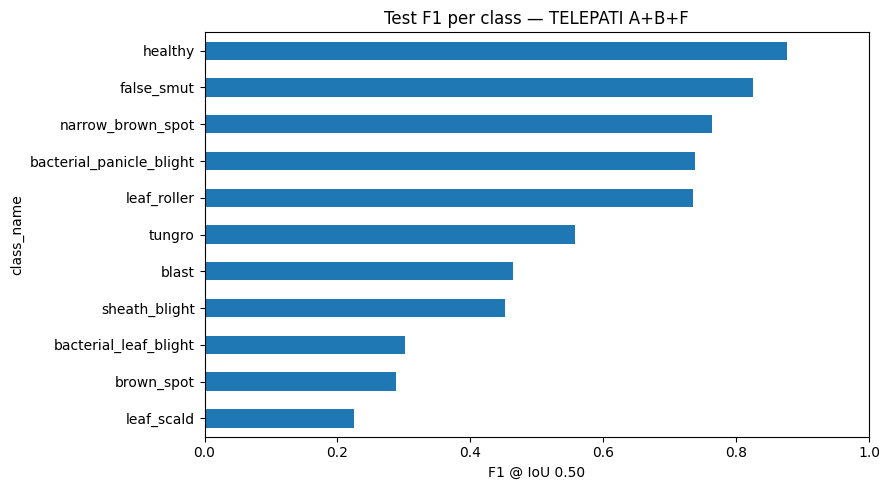

In [33]:
# 18. GRAFIK LOSS/EPOCH + PER-CLASS TEST F1
history_file = RUNS_ROOT/'student_yolo26n_abf_kd'/'results.csv'
if history_file.exists():
    hist=pd.read_csv(history_file)
    hist.columns=[c.strip() for c in hist.columns]
    available=[c for c in ['train/box_loss','train/cls_loss','val/box_loss','val/cls_loss'] if c in hist]
    if available:
        ax=hist[available].plot(figsize=(9,4), title='YOLO26n A+B+F — Training and validation losses')
        ax.set_xlabel('Epoch (index from 0)');ax.set_ylabel('Loss')
        plt.tight_layout();plt.show()
else:
    print('results.csv tidak tersedia jika student dimuat dari checkpoint eksternal.')
ax=test_per_class.sort_values('f1').plot(kind='barh',x='class_name',y='f1',legend=False,figsize=(9,5))
ax.set_xlim(0,1);ax.set_xlabel('F1 @ IoU 0.50')
ax.set_title('Test F1 per class — TELEPATI A+B+F')
plt.tight_layout();plt.savefig(EVAL_ROOT/'test_per_class_f1.png',dpi=180);plt.show()


In [34]:
# 19. EXPORT SUMMARY & ZIP OUTPUT (best YOLO26n + eval, optional teacher weights)
config = {
    'method':'A+B+F', 'student_arch':'YOLO26n', 'teacher_arch':'YOLO26s',
    'student_epochs_max':STUDENT_EPOCHS,'teacher_epochs_max':TEACHER_EPOCHS,
    'class_aware_fraction':OVERSAMPLE_FRACTION,'rare_power':RARE_POWER,
    'distill_model':str(TEACHER_BEST_PT),'dis':KD_WEIGHT,
    'imgsz':IMGSZ,'batch_student':BATCH_STUDENT,'batch_teacher':BATCH_TEACHER,
    'names':CANONICAL_NAMES,'seed':SEED,'matching_iou':MATCH_IOU,
    'confidence_threshold_selected_on_validation':BEST_CONF,
    'aug':AUGMENT_PARAMS,
}
(EXPORT_ROOT/'experiment_config.json').write_text(json.dumps(config,indent=2))
package = WORK_ROOT / 'TELEPATI_YOLO26n_ABF_KD_results.zip'
with zipfile.ZipFile(package,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    z.write(FINAL_PT,'best_yolo26n_abf_kd.pt')
    for directory,prefix in [(EVAL_ROOT,'evaluation'),(EXPORT_ROOT,'config')]:
        for p in directory.rglob('*'):
            if p.is_file() and p.suffix.lower() in {'.csv','.json','.png'}:
                z.write(p, f'{prefix}/{p.relative_to(directory).as_posix()}')
print('FINAL PT :',FINAL_PT)
print('ZIP FILE :',package)
print('ZIP SIZE :',round(package.stat().st_size/1024**2,1),'MB')
# Opsional Colab: uncomment dua baris berikut untuk unduh.
# from google.colab import files
# files.download(str(package))


FINAL PT : /kaggle/working/telepati_abf/exports/best_yolo26n_abf_kd.pt
ZIP FILE : /kaggle/working/TELEPATI_YOLO26n_ABF_KD_results.zip
ZIP SIZE : 29.5 MB


## Catatan eksperimen

- **Metode:** YOLO26n fine-tuning (A), training-only class-aware oversampling + augmentasi online (B), dan **feature-level teacher-student KD** via Ultralytics `distill_model` (F).
- **Teacher:** YOLO26s, dipelajari pada 11 kelas dataset yang sama. Kalau KD ternyata tidak meningkatkan skor validasi, naik-turunkan `KD_WEIGHT` secara **validation-only**, bukan test. Untuk kontrol eksperimen, jalankan `RUN_ABLATION_AB=True`.
- **Performa:** belum ada angka hasil dari notebook baru sampai training benar-benar dijalankan. Nilai `Macro F1` lama bukan baseline yang apple-to-apple karena ensemble/TTA/WBF lama berbeda dengan student tunggal ini.
- **Validitas:** audit alias ambigu, exact duplicates lintas split, dan potensi near-duplicates perlu ditinjau sebelum klaim generalisasi. Exact MD5 tidak mendeteksi near-duplicates.
- **Batas Kaggle:** ketika kernel berhenti, simpan `best.pt` dan ZIP dari Output; untuk continue training bisa menggunakan checkpoint terakhir pada run (Ultralytics `resume=True`).